# 05 - Evaluation results

Every table and chart here is rebuilt from tracked files only. Charts are saved
to `assets/figures/`.

In [1]:
import json, csv
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
ROOT = Path("..").resolve()
FIG = ROOT / "assets" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

## Held-out table (original test split)

In [2]:
dev = json.load(open(ROOT / "results" / "eval_dev.json", encoding="utf-8"))
test = json.load(open(ROOT / "results" / "eval_test.json", encoding="utf-8"))
print("dev records:", len(dev["records"]), "test records:", len(test["records"]))
print("dev exact:", dev["metrics"]["exact_accuracy"] if "metrics" in dev else "see report")
print("test exact:", test["metrics"]["exact_accuracy"] if "metrics" in test else "see report")

dev records: 10 test records: 20
dev exact: 0.8
test exact: 0.6


## Stage of failure (bar chart)

stage       label count share_of_failures                                     claims
    R   Retrieval     2            0.1538                              row 5; row 17
    P     Passage     3            0.2308                      row 21; row 4; row 12
    N         NLI     6            0.4615 row 6; row 7; row 8; row 9; row 10; live 3
    A Aggregation     1            0.0769                                     live 2
    C       Claim     1            0.0769                                     live 4
    L       Label     0            0.0000                                           
Total                13            1.0000                                           


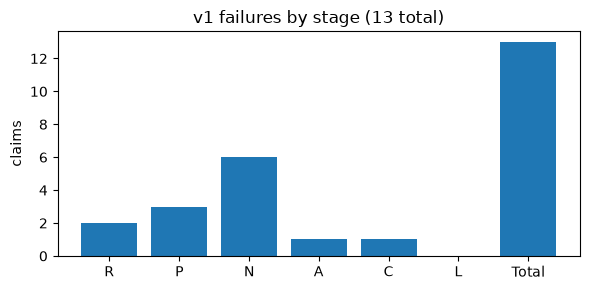

In [3]:
import csv
stage = list(csv.DictReader(open(ROOT / "notes" / "diagnosis_stage_counts.csv", encoding="utf-8", newline="")))
# notes is gitignored; fall back to a small inline copy if missing
if not stage:
    stage = [{"stage": "N", "count": 6}, {"stage": "P", "count": 3},
             {"stage": "R", "count": 2}, {"stage": "A", "count": 1},
             {"stage": "C", "count": 1}, {"stage": "L", "count": 0}]
df = pd.DataFrame(stage)
print(df.to_string(index=False))
plt.figure(figsize=(6, 3))
plt.bar(df["stage"], df["count"].astype(int))
plt.title("v1 failures by stage (13 total)")
plt.ylabel("claims")
plt.tight_layout()
plt.savefig(FIG / "stage_of_failure.png", dpi=120)
plt.show()

## v3 ablation table

In [4]:
v3 = json.load(open(ROOT / "results" / "v3_ablation.json", encoding="utf-8"))
rows = []
for name, c in v3["configs"].items():
    m = c["metrics_warm"]
    rows.append({"config": name, "exact": m["exact"], "correct_sr": m["correct_sr"],
                 "abstained_sr": m["abstained_sr"], "flips": m["flips"]})
print(pd.DataFrame(rows).to_string(index=False))

config exact correct_sr abstained_sr  flips
    v1 20/30      10/20         9/20      1
     A 18/30       8/20        11/20      1
     B 23/30      13/20         4/20      3
     C 14/30       5/20        15/20      0
   A+B 21/30      11/20         7/20      2
   B+C 20/30      11/20         7/20      2
 A+B+C 20/30      10/20        10/20      0


## Gate table

In [5]:
gt = json.load(open(ROOT / "results" / "gate_table.json", encoding="utf-8"))
print(pd.DataFrame(gt["table"]).to_string(index=False))

                                     gate  kept  removed  lost correct_sr  false_rem  wrong_committed
    min refuting articles >= 2 (baseline)    10        0     0      13/35          0                5
               min refuting articles >= 3     9        4     1      12/35          4                1
          min relevance >= 0.5 (baseline)    10        0     0      13/35          0                5
                     min relevance >= 0.6     9        0     1      12/35          0                5
                     min relevance >= 0.7     7        1     3      10/35          1                4
                     min relevance >= 0.8     1        4     9       4/35          4                1
                      min p_contra >= 0.9     9        2     1      12/35          2                3
                     min p_contra >= 0.95     8        3     2      11/35          3                2
                     min p_contra >= 0.99     6        3     4       9/35         

## Combined 60-claim table

In [6]:
summary = json.load(open(ROOT / "results" / "fresh20_summary.json", encoding="utf-8"))
print(json.dumps(summary, indent=2))
print("combined table is in README and notes/fresh20_results.md")

{
  "v1": {
    "n": 20,
    "exact": "8/20",
    "correct_sr": "3/15",
    "abstained_sr": "8/15",
    "flips": 4,
    "unv_wrong": 0,
    "wrong_committed": 4,
    "exact_count": 8,
    "correct_sr_count": 3,
    "abstained_sr_count": 8
  },
  "v3": {
    "n": 20,
    "exact": "4/20",
    "correct_sr": "0/15",
    "abstained_sr": "12/15",
    "flips": 3,
    "unv_wrong": 1,
    "wrong_committed": 4,
    "exact_count": 4,
    "correct_sr_count": 0,
    "abstained_sr_count": 12
  },
  "v1_mean_lat": 920714.9,
  "v3_mean_lat": 9047.8
}
combined table is in README and notes/fresh20_results.md


## Save a placeholder chart for the ablation

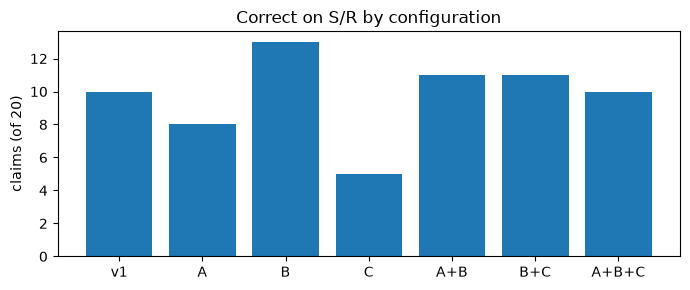

notebook 05 complete


In [7]:
v3 = json.load(open(ROOT / "results" / "v3_ablation.json", encoding="utf-8"))
names = list(v3["configs"].keys())
correct = [v3["configs"][n]["metrics_warm"]["correct_sr_count"] for n in names]
plt.figure(figsize=(7, 3))
plt.bar(names, correct)
plt.title("Correct on S/R by configuration")
plt.ylabel("claims (of 20)")
plt.tight_layout()
plt.savefig(FIG / "v3_ablation.png", dpi=120)
plt.show()
print("notebook 05 complete")